# Aplicação estratégica: o que o modelo diz sobre os municípios

Tech Challenge, Fase 3 (Pós Tech). Terceiro notebook do projeto.

Este notebook usa o modelo treinado em `02_modelagem.ipynb` (`reports/modelo_final.joblib`) e os achados da EDA para responder às perguntas de negócio do enunciado: quais fatores mais impactam a alfabetização, quais municípios têm maior risco, quais regiões têm padrões semelhantes, como olhar para metas futuras e quais variáveis mais influenciam os modelos.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.modeling.pipeline import SEED
from src.preprocessing.features import ALVO, CATEGORICAS, NUMERICAS, carrega_abt, monta_features
from src.visualization import plots

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

REPORTS = RAIZ / "reports"

## Dados e modelo

Usamos a mesma ABT e o mesmo escopo da modelagem: 4.811 municípios, sem o RS, que ficou fora do treino por ter sofrido um choque em 2024. O modelo carregado é a random forest treinada com todos esses municípios.

In [2]:
abt = carrega_abt()
rs = abt["sigla_uf"] == "RS"
X_todos = monta_features(abt, ano_base=2023, ano_alvo=2024)
X, y = X_todos[~rs], abt.loc[~rs, ALVO]
modelo = joblib.load(REPORTS / "modelo_final.joblib")

print(f"{len(X):,} municípios na modelagem (sem o RS) | {len(abt):,} na ABT")
print("modelo:", type(modelo.named_steps["modelo"]).__name__)

4,811 municípios na modelagem (sem o RS) | 5,232 na ABT
modelo: RandomForestClassifier


## 1. Quais fatores mais impactam a alfabetização?

Essa pergunta e a última do enunciado (quais variáveis mais influenciam os modelos) têm a mesma resposta. A tabela traz a importância por permutação do `02_modelagem.ipynb`: a queda do AUC quando cada variável é embaralhada no teste.

In [3]:
pd.read_csv(REPORTS / "importancia_variaveis.csv", index_col=0).round(3)

,queda_do_auc,desvio
macrorregiao,0.110,0.012
participacao_base,0.066,0.008
taxa_base,0.053,0.009
media_portugues_base,0.043,0.007
log_populacao,0.026,0.007
log_pib_per_capita,-0.004,0.004


Juntando a permutação, o SHAP e a EDA:

A participação na avaliação é o fator mais acionável. É a variável de maior impacto no SHAP e, na EDA, o percentual de municípios que cumprem a meta vai de 40% no quintil de menor participação para 65% no de maior, com diferença de 16 a 18 p.p. dentro de cada faixa de taxa. A taxa de partida e o porte seguem em importância: quem partia de uma taxa alta tendeu a cair (regressão à média), e os municípios grandes cumprem menos a meta do que os pequenos. A renda (PIB per capita) explica o nível da taxa, mas não o cumprimento da meta. O esforço exigido, o quanto a meta pedia a mais do que a taxa de 2023, também não explica.

A macrorregião aparece com o maior peso na permutação. Parte desse peso reflete o desempenho de cada região em 2024 e não uma propriedade estável dela. Tudo isso é associação e não causa.

## 2. Quais municípios têm maior risco educacional?

Para pontuar todos os municípios sem usar o mesmo dado no treino e na previsão, usamos previsões fora da amostra: cada município é pontuado por um modelo que não o viu. O risco é 1 menos a probabilidade prevista de cumprir a meta. O RS não entra nesta tabela porque ficou fora do treino.

In [4]:
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
p_cumpre = cross_val_predict(clone(modelo), X, y, cv=cv_oof, method="predict_proba")[:, 1]

risco = X[["id_municipio", "nome_geografia", "sigla_uf", "taxa_base", "participacao_base"]].copy()
risco["populacao"] = abt.loc[X.index, "populacao_estimada"].astype(int)
risco["risco"] = 1 - p_cumpre
risco["nao_cumpriu_2024"] = 1 - y
risco = risco.sort_values("risco", ascending=False)
risco.to_csv(REPORTS / "risco_municipios_2024_validacao_cruzada.csv", index=False)

risco["decil"] = pd.qcut(risco["risco"].rank(method="first"), 10, labels=False) + 1
print("risco previsto x observado, por decil (10 = maior risco):")
print(risco.groupby("decil").agg(risco_medio=("risco", "mean"), nao_cumpriu=("nao_cumpriu_2024", "mean")).round(3).T)
risco.head(15).drop(columns=["decil", "nao_cumpriu_2024"]).round(3).reset_index(drop=True)

risco previsto x observado, por decil (10 = maior risco):
decil           1      2      3      4      5      6      7      8      9      10
risco_medio  0.117  0.240  0.306  0.359  0.405  0.448  0.490  0.548  0.628  0.760
nao_cumpriu  0.145  0.225  0.274  0.389  0.380  0.453  0.482  0.551  0.634  0.755


,id_municipio,nome_geografia,sigla_uf,taxa_base,participacao_base,populacao,risco
0,1504422,MARITUBA,PA,57.34,79.20,119859,0.914
1,2103000,CAXIAS,MA,43.75,83.56,163650,0.907
2,2501807,BAYEUX,PB,33.89,73.31,83351,0.903
3,2207702,PARNAIBA,PI,31.00,82.64,171342,0.903
4,2929503,SAO SEBASTIAO DO PASSE,BA,49.95,78.12,42951,0.892
5,2928604,SANTO AMARO,BA,43.81,76.41,58384,0.892
6,2918001,JEQUIE,BA,37.87,76.43,169623,0.892
7,2407807,MONTE ALEGRE,RN,59.18,81.42,24055,0.887
8,2910057,DIAS D'AVILA,BA,35.50,77.76,75516,0.886
9,1302900,MAUES,AM,53.17,78.48,67021,0.883


O ranking funciona. No decil de maior risco o risco previsto médio é 76% e 75,5% desses municípios de fato não cumpriram a meta. No decil de menor risco, 12% previstos contra 14,5% observados. A lista dos mais arriscados é de municípios de porte médio (de 24 mil a 171 mil habitantes) do Nordeste e do Norte, como Marituba (PA), Caxias (MA), Bayeux (PB), Parnaíba (PI) e vários na Bahia. Todos têm taxa abaixo de 60% e participação entre 73% e 84%. Como a previsão é sobre 2024, a lista é retrospectiva: serve para entender o padrão, não para agir sobre aquele ano.

Por UF, a concentração de risco alto (risco previsto de 70% ou mais):

In [5]:
(risco.groupby("sigla_uf")
      .agg(municipios=("risco", "size"), risco_medio=("risco", "mean"),
           pct_risco_alto=("risco", lambda s: (s >= 0.7).mean() * 100))
      .sort_values("pct_risco_alto", ascending=False).round(1).head(8))

,municipios,risco_medio,pct_risco_alto
sigla_uf,,,
AM,48,0.6,41.7
PA,136,0.7,36.8
BA,394,0.6,34.8
RN,139,0.5,22.3
PB,220,0.5,17.7
MA,216,0.5,16.7
RJ,90,0.5,12.2
SE,75,0.5,10.7


A maior concentração está no Amazonas (42% dos municípios), no Pará (37%) e na Bahia (35%), seguidos por Rio Grande do Norte (22%), Paraíba (18%) e Maranhão (17%).

## 3. Quais regiões têm padrões semelhantes?

Agrupamos as UFs com k-means a partir de quatro características estruturais: taxa de 2023, participação, PIB per capita e porte, todas pela mediana da UF e padronizadas. O número de grupos foi escolhido pela silhueta (4 grupos, 0,33). Os resultados de 2024 (percentual que cumpriu e variação) não entram no agrupamento e servem para checar se os grupos fazem sentido.

In [6]:
base_uf = abt.assign(variacao=abt["taxa_alfabetizacao_2024_pct"] - abt["taxa_alfabetizacao_2023_pct"])
uf = base_uf.groupby("sigla_uf").agg(
    municipios=("geo_key", "size"),
    taxa_2023=("taxa_alfabetizacao_2023_pct", "median"),
    participacao=("participacao_2023_pct", "median"),
    log_pib_pc=("log_pib_per_capita", "median"),
    log_pop=("log_populacao", "median"),
    pct_atingiu=("target_atingiu_meta_2024", lambda s: s.mean() * 100),
    variacao=("variacao", "median"),
)
perfil = ["taxa_2023", "participacao", "log_pib_pc", "log_pop"]
Z = StandardScaler().fit_transform(uf[perfil])
silhueta = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 7)}
k_final = max(silhueta, key=silhueta.get)
uf["grupo"] = KMeans(k_final, n_init=20, random_state=SEED).fit_predict(Z)
ordem = uf.groupby("grupo")["taxa_2023"].mean().sort_values().index
uf["grupo"] = uf["grupo"].map({g: i + 1 for i, g in enumerate(ordem)})

print("silhueta por número de grupos:", {k: round(v, 3) for k, v in silhueta.items()}, "-> k =", k_final)
for g, d in uf.groupby("grupo"):
    print(f"grupo {g}: {', '.join(d.index)}")
uf.groupby("grupo")[perfil + ["pct_atingiu", "variacao", "municipios"]].agg(
    {"taxa_2023": "mean", "participacao": "mean", "log_pib_pc": "mean", "log_pop": "mean",
     "pct_atingiu": "mean", "variacao": "mean", "municipios": "sum"}).round(1)

silhueta por número de grupos: {2: 0.249, 3: 0.301, 4: 0.328, 5: 0.317, 6: 0.281} -> k = 4
grupo 1: AP, BA, RN, SE, TO
grupo 2: AM, PA, RJ
grupo 3: AL, CE, MA, MG, PB, PE, PI
grupo 4: ES, GO, MS, MT, PR, RO, RS, SC, SP


,taxa_2023,participacao,log_pib_pc,log_pop,pct_atingiu,variacao,municipios
grupo,,,,,,,
1,35.1,88.1,10.0,9.2,43.3,4.9,761
2,50.4,81.6,9.9,10.4,33.6,0.5,274
3,61.0,93.9,9.7,9.4,64.0,5.2,1931
4,66.2,89.6,10.7,9.3,55.7,1.4,2266


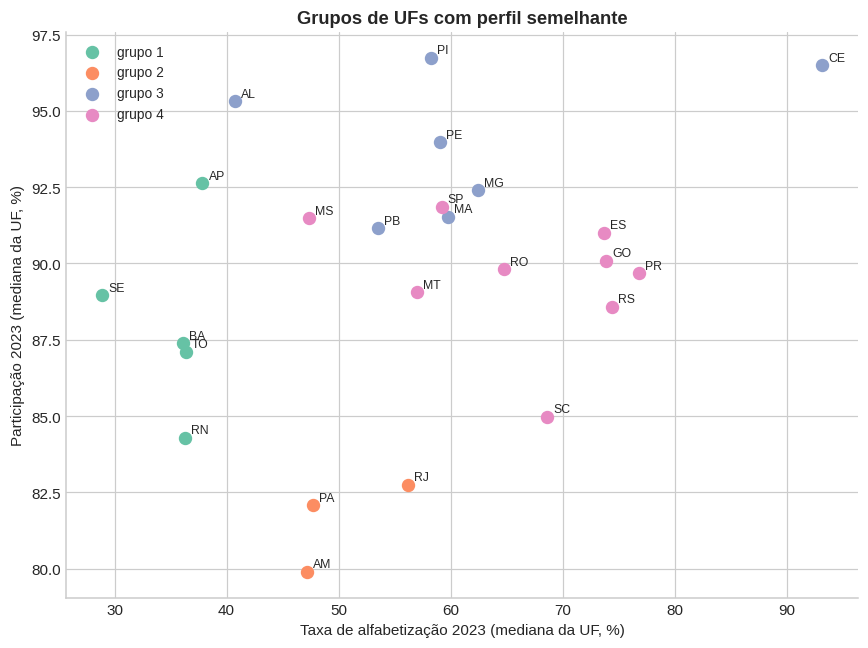

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
paleta = sns.color_palette("Set2", k_final)
for g, d in uf.groupby("grupo"):
    ax.scatter(d["taxa_2023"], d["participacao"], s=60, color=paleta[g - 1], label=f"grupo {g}")
    for sigla, linha in d.iterrows():
        ax.annotate(sigla, (linha["taxa_2023"], linha["participacao"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Taxa de alfabetização 2023 (mediana da UF, %)")
ax.set_ylabel("Participação 2023 (mediana da UF, %)")
ax.set_title("Grupos de UFs com perfil semelhante")
ax.legend(fontsize=9)
plt.tight_layout()
plots.salva(fig, "11_grupos_de_ufs.png")

Os quatro grupos têm leituras diferentes. O grupo 1 (AP, BA, RN, SE e TO) tem a taxa mais baixa (35%) e 43% dos municípios cumprindo a meta. O grupo 2 (AM, PA e RJ) tem nível médio (50%), a menor participação (82%) e os municípios maiores, e é o de pior resultado: 34% cumpriram e a variação foi de apenas 0,5 p.p. O grupo 3 (AL, CE, MA, MG, PB, PE e PI) tem taxa de 61%, a maior participação (94%) e 64% de cumprimento, com avanço de 5,2 p.p. O grupo 4 (ES, GO, MS, MT, PR, RO, RS, SC e SP) tem o nível mais alto (66%) e o maior PIB per capita, com 56% de cumprimento, puxado para baixo pelo RS.

O grupo de menor PIB per capita é também o de maior cumprimento, e o que separa os grupos é mais a participação do que a renda.

## 4. Como prever municípios que podem não atingir metas futuras?

Para 2025 usamos a taxa e a participação de 2024 como base e a meta de 2025. O modelo pontua os 5.232 municípios, incluindo o RS. Há um problema que só aparece aqui: a meta de 2025 continua ancorada na taxa de 2023 e não na de 2024. Para quem mudou muito de patamar em 2024, a distância até a meta fica fora do que o modelo viu no treino, em que nenhum município precisou avançar mais de 7,2 p.p.

In [8]:
X25 = monta_features(abt, ano_base=2024, ano_alvo=2025)
risco_modelo = 1 - modelo.predict_proba(X25[NUMERICAS + CATEGORICAS])[:, 1]

futuro = X25[["id_municipio", "nome_geografia", "sigla_uf", "taxa_base", "esforco_meta"]].rename(
    columns={"taxa_base": "taxa_2024", "esforco_meta": "distancia_meta_2025_pp"})
limite_treino = X["esforco_meta"].max()
futuro["fora_do_suporte"] = futuro["distancia_meta_2025_pp"] > limite_treino

variacao_hist = (abt["taxa_alfabetizacao_2024_pct"] - abt["taxa_alfabetizacao_2023_pct"])[~rs].to_numpy()
print(f"maior distância até a meta vista no treino: {limite_treino:.1f} p.p.")
print(f"municípios com meta de 2025 além disso: {futuro['fora_do_suporte'].sum():,} de {len(futuro):,}\n")
print("frequência com que um município (fora do RS) avançou pelo menos X p.p. de 2023 para 2024:")
for g in (7.3, 10, 15, 20, 30):
    print(f"  {g:>4} p.p.: {(variacao_hist >= g).mean():.1%}")

maior distância até a meta vista no treino: 7.2 p.p.
municípios com meta de 2025 além disso: 1,881 de 5,232

frequência com que um município (fora do RS) avançou pelo menos X p.p. de 2023 para 2024:
   7.3 p.p.: 38.7%
    10 p.p.: 31.6%
    15 p.p.: 21.3%
    20 p.p.: 13.9%
    30 p.p.: 5.5%


Isso atinge 1.881 dos 5.232 municípios (36%), e para eles o modelo estaria extrapolando. A saída simples foi usar o histórico: quando a distância até a meta passa do máximo visto no treino, o risco vem da frequência com que os municípios (fora do RS) avançaram aquela distância entre 2023 e 2024. Avançar pelo menos 7,3 p.p. aconteceu em 38,7% dos casos, 15 p.p. em 21,3% e 20 p.p. em 13,9%. É uma aproximação grosseira, porque ignora o ponto de partida de cada município e a regressão à média, mas é transparente quanto ao que os dados sustentam. Dentro do suporte do treino, vale o modelo.

In [9]:
def prob_avanco(distancia):
    return (variacao_hist >= distancia).mean()


futuro["risco_modelo"] = risco_modelo
risco_hist = 1 - futuro["distancia_meta_2025_pp"].apply(prob_avanco)
futuro["risco_2025"] = np.where(futuro["fora_do_suporte"], risco_hist, futuro["risco_modelo"])
futuro["faixa"] = pd.cut(futuro["risco_2025"], [-0.01, 0.4, 0.6, 0.8, 1.0],
                         labels=["baixo", "médio", "alto", "muito alto"])
futuro = futuro.sort_values("risco_2025", ascending=False)
futuro.to_csv(REPORTS / "risco_metas_2025.csv", index=False)

print(futuro["faixa"].value_counts().reindex(["baixo", "médio", "alto", "muito alto"]).to_dict())
por_uf_2025 = (futuro.groupby("sigla_uf")
               .agg(municipios=("risco_2025", "size"),
                    pct_alto_ou_muito_alto=("faixa", lambda s: s.isin(["alto", "muito alto"]).mean() * 100))
               .sort_values("pct_alto_ou_muito_alto", ascending=False).round(1))
print(por_uf_2025.head(8).T.to_string())
futuro.head(12).drop(columns=["faixa"]).round(2).reset_index(drop=True)

{'baixo': 1419, 'médio': 1575, 'alto': 1332, 'muito alto': 906}
sigla_uf                   BA     PA     RS     RN    AM    SE     PB     MA
municipios              394.0  136.0  421.0  139.0  48.0  75.0  220.0  216.0
pct_alto_ou_muito_alto   84.5   83.8   83.6   81.3  79.2  66.7   60.5   57.9


,id_municipio,nome_geografia,sigla_uf,taxa_2024,distancia_meta_2025_pp,fora_do_suporte,risco_modelo,risco_2025
0,4320453,SERIO,RS,11.10,68.90,True,0.24,1.00
1,4301073,ARROIO DO PADRE,RS,18.20,61.80,True,0.12,1.00
2,4319208,SAO NICOLAU,RS,7.10,58.00,True,0.09,1.00
3,4310850,JABOTICABA,RS,25.00,55.00,True,0.20,1.00
4,4319752,SAO VENDELINO,RS,25.00,55.00,True,0.27,1.00
5,4306700,DONA FRANCISCA,RS,26.70,53.30,True,0.27,1.00
6,4302584,BOZANO,RS,27.30,52.70,True,0.32,1.00
7,1713601,MONTE DO CARMO,TO,19.71,53.39,True,0.24,1.00
8,4320354,SENTINELA DO SUL,RS,23.50,52.20,True,0.22,1.00
9,1704600,CHAPADA DE AREIA,TO,6.25,53.52,True,0.22,1.00


O resultado são 906 municípios na faixa "muito alto" e 1.332 em "alto". A concentração de risco alto ou muito alto é maior na Bahia (84,5% dos municípios), no Pará (83,8%), no Rio Grande do Sul (83,6%), no Rio Grande do Norte (81,3%) e no Amazonas (79,2%). O topo da lista é de municípios gaúchos, tocantinenses e de outros estados cuja taxa de 2024 ficou cerca de 50 p.p. ou mais abaixo da meta de 2025, casos que o modelo sozinho chamaria de risco baixo (0,09 a 0,33). Esse contraste é a razão de a regra existir.

Como a faixa "fora do suporte" tem outra origem, a leitura correta é de ranking e de faixas, e não de probabilidade calibrada. Quando saírem os resultados de 2025, basta repetir o treino com `monta_features(abt, 2024, 2025)`.